# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:

df = pd.read_csv('./data/metabric.csv')
df['Overall Survival Status'].value_counts()

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64

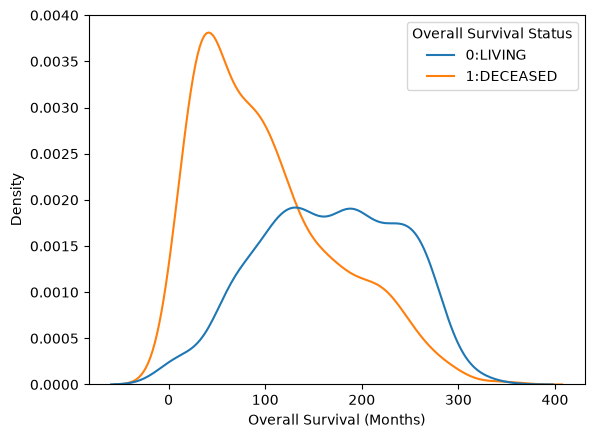

In [3]:
df = df[df['Tumor Stage'] != 0].copy()

sns.kdeplot(df, x='Overall Survival (Months)',  hue='Overall Survival Status')
plt.show()

2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
import statsmodels.api as sm

In [5]:
df['log_months'] = np.log(df['Overall Survival (Months)'])
df['log_months'].describe()

count    1341.000000
mean        4.588585
std         0.876023
min        -2.302585
25%         4.139424
50%         4.775194
75%         5.253146
max         5.860786
Name: log_months, dtype: float64

In [6]:
num = ['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count', 'Tumor Size']
cat = ['Chemotherapy', 'Hormone Therapy', 'Radio Therapy', 'Tumor Stage']

X = pd.get_dummies(df[num + cat], drop_first=True)
X = sm.add_constant(X)
X = X.astype(float)
y = df['log_months']

X.head()

,const,Age at Diagnosis,Lymph nodes examined positive,Mutation Count,Tumor Size,Tumor Stage,Chemotherapy_YES,Hormone Therapy_YES,Radio Therapy_YES
0,1.0,43.19,0.0,2.0,10.0,1.0,0.0,1.0,1.0
1,1.0,48.87,1.0,2.0,15.0,2.0,1.0,1.0,0.0
2,1.0,47.68,3.0,1.0,25.0,2.0,1.0,1.0,1.0
3,1.0,76.97,8.0,2.0,40.0,2.0,1.0,1.0,1.0
4,1.0,78.77,0.0,4.0,31.0,4.0,0.0,1.0,1.0


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2)
ols_impute = sm.OLS(y_train, X_train).fit()
pred_impute = ols_impute.predict(X_test)

ols_impute.params

const                            5.580091
Age at Diagnosis                -0.010964
Lymph nodes examined positive   -0.036649
Mutation Count                   0.008680
Tumor Size                      -0.002154
Tumor Stage                     -0.207806
Chemotherapy_YES                -0.201918
Hormone Therapy_YES              0.136564
Radio Therapy_YES                0.114963
dtype: float64

In [8]:
dead = df[df['Overall Survival Status'] == '1:DECEASED']
X_dead = pd.get_dummies(dead[num + cat], drop_first=True)
X_dead = sm.add_constant(X_dead)
X_dead = X_dead.astype(float)
y_dead = dead['log_months']

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_dead, y_dead, test_size=.2)
ols_drop = sm.OLS(y_train_d, X_train_d).fit()
pred_drop = ols_drop.predict(X_test_d)

ols_drop.params

const                            5.033030
Age at Diagnosis                -0.002402
Lymph nodes examined positive   -0.027885
Mutation Count                   0.002605
Tumor Size                       0.000293
Tumor Stage                     -0.284125
Chemotherapy_YES                -0.403413
Hormone Therapy_YES              0.213002
Radio Therapy_YES               -0.047183
dtype: float64

* first way is imputation. for people still alive the recorded months is just how long we've watched them, not how long they actually survive. We're plugging that censored number in as if it were the true survival time.

* second way treats the censored cases as missing and drops them. We only fit on people who died, so the sample is tilted toward shorter survival.

3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).å

For people who died, log-months is actually observed, so their piece of the log-likelihood is just the normal density (same as regular normal regression):

$$\ell_i = -\log(\sigma) - \frac{(y_i - x_i\beta)^2}{2\sigma^2}$$

For people still alive, we only know their true log-months is bigger than the recorded number, so we use the normal survival probability instead:

$$\ell_i = \log\bigl(1 - \Phi\bigl(\frac{y_i - x_i\beta}{\sigma}\bigr)\bigr)$$

Total log-likelihood is just the sum of density for the dead and survival for the living.

4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.

In [9]:
from statsmodels.base.model import GenericLikelihoodModel
from scipy.stats import norm

In [10]:
df['event'] = (df['Overall Survival Status'] == '1:DECEASED').astype(int)
df['event'].value_counts()

event
1    768
0    573
Name: count, dtype: int64

In [15]:
train = df.loc[X_train.index]
X_train = X.loc[train.index]
y_train = train['log_months']
train
X_train
y_train

1054    4.775194
514     3.303217
864     3.077312
973     3.632309
387     4.577456
          ...   
1280    5.185335
803     5.477857
206     4.580536
87      4.258917
1158    5.082232
Name: log_months, Length: 1072, dtype: float64

In [16]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_impute.params, np.log(np.sqrt(np.mean(ols_impute.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
mle.summary()

Converged: True


<class 'statsmodels.iolib.summary.Summary'>
"""
                          CensoredNormalMLE Results                           
==============================================================================
Dep. Variable:             log_months   Log-Likelihood:                -1182.7
Model:              CensoredNormalMLE   AIC:                             2385.
Method:            Maximum Likelihood   BIC:                             2435.
Date:                Tue, 17 Nov 2026                                         
Time:                        16:11:21                                         
No. Observations:                1072                                         
Df Residuals:                    1062                                         
Df Model:                           8                                         
=================================================================================================
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             7.2287      0.236     30.657      0.000       6.767       7.691
Age at Diagnosis                 -0.0272      0.003     -8.097      0.000      -0.034      -0.021
Lymph nodes examined positive    -0.0562      0.011     -5.242      0.000      -0.077      -0.035
Mutation Count                   -0.0102      0.010     -1.068      0.285      -0.029       0.008
Tumor Size                       -0.0042      0.003     -1.443      0.149      -0.010       0.002
Tumor Stage                      -0.3069      0.078     -3.939      0.000      -0.460      -0.154
Chemotherapy_YES                 -0.3121      0.113     -2.754      0.006      -0.534      -0.090
Hormone Therapy_YES               0.3229      0.081      3.998      0.000       0.165       0.481
Radio Therapy_YES                 0.2030      0.078      2.595      0.009       0.050       0.356
log_sigma                         0.0575      0.030      1.917      0.055      -0.001       0.116
=================================================================================================
"""

5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [17]:
coef = pd.DataFrame({
    'impute': ols_impute.params,
    'drop': ols_drop.params,
    'censored': mle.params[:-1]
})
coef

,impute,drop,censored
const,5.580091,5.033030,7.228705
Age at Diagnosis,-0.010964,-0.002402,-0.027220
Lymph nodes examined positive,-0.036649,-0.027885,-0.056155
Mutation Count,0.008680,0.002605,-0.010167
Tumor Size,-0.002154,0.000293,-0.004238
Tumor Stage,-0.207806,-0.284125,-0.306875
Chemotherapy_YES,-0.201918,-0.403413,-0.312108
Hormone Therapy_YES,0.136564,0.213002,0.322942
Radio Therapy_YES,0.114963,-0.047183,0.202967


In [18]:
pred_mle = X_test @ mle.params[:-1]
pred_mle.head()

15      5.290901
879     4.759096
381     4.745622
704     4.420635
1324    4.158651
dtype: float64

In [19]:
test = df.loc[X_test.index].copy()
test['pred_impute'] = pred_impute
test['pred_mle'] = pred_mle
test['pred_drop'] = X_test @ ols_drop.params

test.groupby('Overall Survival Status')[['log_months', 'pred_impute', 'pred_drop', 'pred_mle']].mean()

,log_months,pred_impute,pred_drop,pred_mle
Overall Survival Status,,,,
0:LIVING,4.946344,4.699748,4.427767,5.263748
1:DECEASED,4.280018,4.489435,4.310020,4.839137


The imputation model treats the living people's recorded months as finished, so it pulls their predictions down. The drop model only saw people who died, so it under-predicts anyone still alive and shifts things like chemo and stage. The censored MLE gives higher predictions for the living, which makes sense once you stop treating censored times as real survival.